Activity 2: Binary Classification – Telecom Customer Churn (Logistic Regression)

In [1]:
import warnings; warnings.filterwarnings('ignore')
import sys, sklearn, statsmodels
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score)

SEED = 42
np.random.seed(SEED)
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| statsmodels', statsmodels.__version__)

Python 3.13.5 | pandas 2.2.3 | scikit-learn 1.6.1 | statsmodels 0.14.4


In [2]:
df = pd.read_csv('telco.csv')
print('Rows, columns:', df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
print(df[['SeniorCitizen', 'tenure', 'MonthlyCharges']].describe().round(2))
print('\nDuplicate customerIDs:', df['customerID'].duplicated().sum())
print('Fully duplicated rows (with ID):', df.duplicated().sum())
print('Target labels:', df['Churn'].unique())

       SeniorCitizen   tenure  MonthlyCharges
count        7043.00  7043.00         7043.00
mean            0.16    32.37           64.76
std             0.37    24.56           30.09
min             0.00     0.00           18.25
25%             0.00     9.00           35.50
50%             0.00    29.00           70.35
75%             0.00    55.00           89.85
max             1.00    72.00          118.75

Duplicate customerIDs: 0
Fully duplicated rows (with ID): 0
Target labels: ['No' 'Yes']


In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges after conversion:', df['TotalCharges'].isna().sum())
print('Their tenure values:'); print(df.loc[df['TotalCharges'].isna(), 'tenure'].value_counts())

Missing TotalCharges after conversion: 11
Their tenure values:
tenure
0    11
Name: count, dtype: int64


In [6]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
ids = df['customerID']                       
df = df.drop(columns='customerID')
df['Churn'] = (df['Churn'] == 'Yes').astype(int)   # 1 = churn (positive class), 0 = stay
print('Rows identical after dropping the ID:', df.duplicated().sum())

Rows identical after dropping the ID: 22


Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    73.5 %
1    26.5 %
Name: count, dtype: object


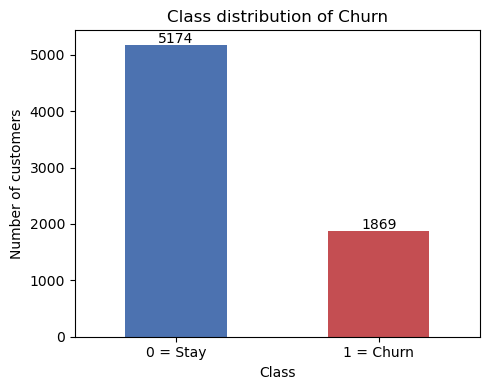

In [7]:
counts = df['Churn'].value_counts().sort_index()
print(counts); print((counts / len(df) * 100).round(1).astype(str) + ' %')
plt.figure(figsize=(5, 4))
ax = counts.plot.bar(color=['#4C72B0', '#C44E52'])
ax.set_xticklabels(['0 = Stay', '1 = Churn'], rotation=0)
ax.set_title('Class distribution of Churn'); ax.set_xlabel('Class'); ax.set_ylabel('Number of customers')
for i, v in enumerate(counts): ax.text(i, v + 40, str(v), ha='center')
plt.tight_layout(); plt.show()

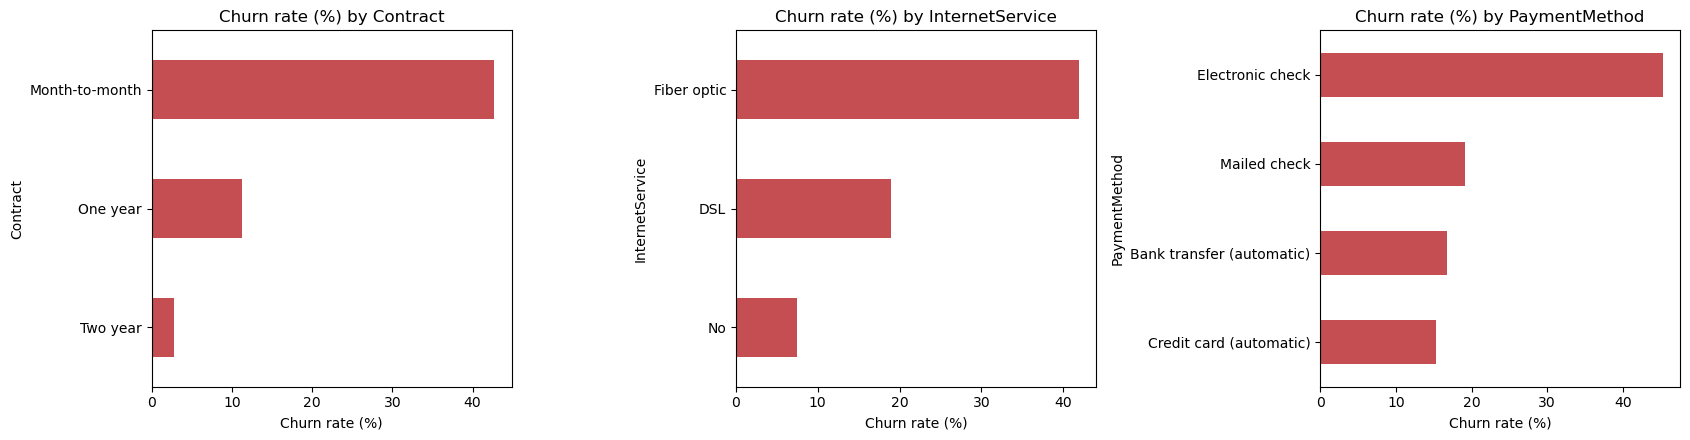

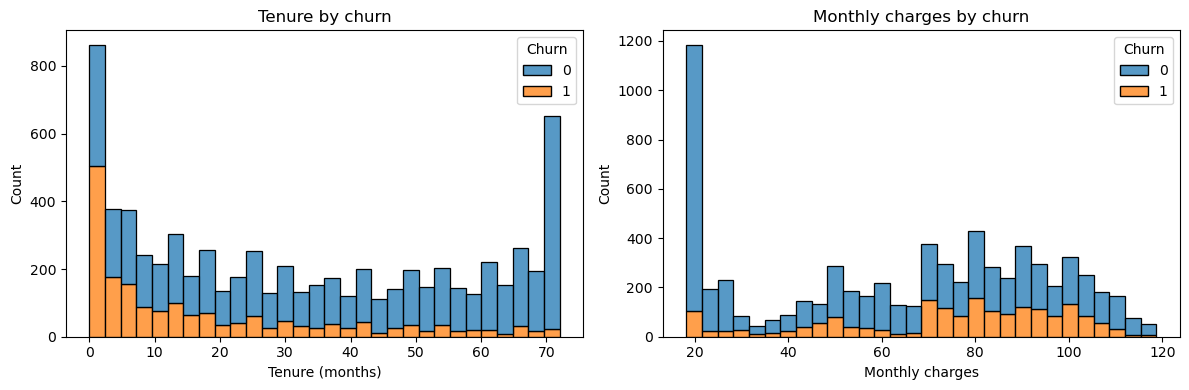

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, c in zip(ax, ['Contract', 'InternetService', 'PaymentMethod']):
    rate = df.groupby(c)['Churn'].mean().sort_values() * 100
    rate.plot.barh(ax=a, color='#C44E52'); a.set_title(f'Churn rate (%) by {c}'); a.set_xlabel('Churn rate (%)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack', ax=ax[0]); ax[0].set_title('Tenure by churn'); ax[0].set_xlabel('Tenure (months)')
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=30, multiple='stack', ax=ax[1]); ax[1].set_title('Monthly charges by churn'); ax[1].set_xlabel('Monthly charges')
plt.tight_layout(); plt.show()

In [9]:
for c in ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']:
    df[c] = df[c].replace({'No internet service': 'No', 'No phone service': 'No'})

X = pd.get_dummies(df.drop(columns='Churn'), drop_first=True).astype(float)
y = df['Churn']
print('Feature matrix:', X.shape)

Feature matrix: (7043, 23)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Training set :', X_train.shape[0], 'rows | class counts ->', y_train.value_counts().sort_index().to_dict(),
      '| churn rate = %.3f' % y_train.mean())
print('Testing set  :', X_test.shape[0], 'rows | class counts ->', y_test.value_counts().sort_index().to_dict(),
      '| churn rate = %.3f' % y_test.mean())

Training set : 5634 rows | class counts -> {0: 4139, 1: 1495} | churn rate = 0.265
Testing set  : 1409 rows | class counts -> {0: 1035, 1: 374} | churn rate = 0.265


In [11]:
def vif_table(Xdf):
    Xc = sm.add_constant(Xdf)
    return (pd.DataFrame({'feature': Xdf.columns,
                          'VIF': [variance_inflation_factor(Xc.values, i + 1) for i in range(Xdf.shape[1])]})
            .sort_values('VIF', ascending=False).reset_index(drop=True))
print('VIF on training data, all features:'); print(vif_table(X_train).head(6).round(1))

drop_cols = ['MonthlyCharges', 'TotalCharges']
X_train_r, X_test_r = X_train.drop(columns=drop_cols), X_test.drop(columns=drop_cols)
print('\nAfter dropping', drop_cols, '-> max VIF = %.2f' % vif_table(X_train_r)['VIF'].max())

VIF on training data, all features:
                       feature    VIF
0               MonthlyCharges  861.9
1  InternetService_Fiber optic  147.8
2           InternetService_No  103.1
3             PhoneService_Yes   35.3
4              StreamingTV_Yes   24.0
5          StreamingMovies_Yes   24.0

After dropping ['MonthlyCharges', 'TotalCharges'] -> max VIF = 2.79


In [12]:
scaler = StandardScaler().fit(X_train_r)                      # learn mean/std from TRAINING data only
Xtr = pd.DataFrame(scaler.transform(X_train_r), columns=X_train_r.columns, index=X_train_r.index)
Xte = pd.DataFrame(scaler.transform(X_test_r),  columns=X_test_r.columns,  index=X_test_r.index)
print('Train mean of tenure after scaling: %.2f | std: %.2f' % (Xtr['tenure'].mean(), Xtr['tenure'].std()))

Train mean of tenure after scaling: -0.00 | std: 1.00


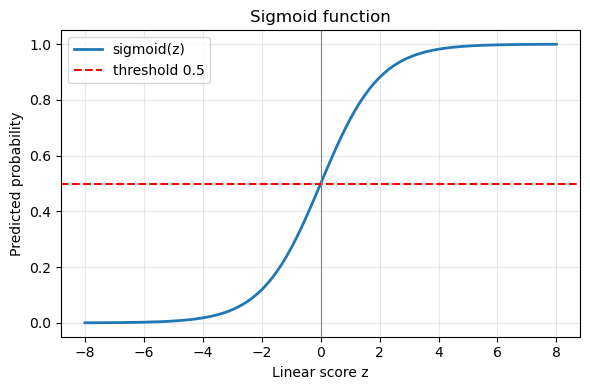

In [13]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 4))
plt.plot(z, 1 / (1 + np.exp(-z)), lw=2, label='sigmoid(z)')
plt.axhline(0.5, color='r', ls='--', label='threshold 0.5'); plt.axvline(0, color='gray', lw=0.8)
plt.title('Sigmoid function'); plt.xlabel('Linear score z'); plt.ylabel('Predicted probability'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [14]:
model = LogisticRegression(max_iter=1000, random_state=SEED)      # default L2 penalty, C=1.0, lbfgs solver
model.fit(Xtr, y_train)
print('Settings:', model.get_params())
print('\nIntercept (b0): %.3f' % model.intercept_[0])
coef = pd.DataFrame({'coefficient': model.coef_[0], 'odds_ratio': np.exp(model.coef_[0])}, index=Xtr.columns)
coef.sort_values('coefficient').round(3)

Settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Intercept (b0): -1.637


,coefficient,odds_ratio
tenure,-0.802,0.449
Contract_Two year,-0.577,0.561
InternetService_No,-0.342,0.710
Contract_One year,-0.284,0.753
OnlineSecurity_Yes,-0.178,0.837
TechSupport_Yes,-0.155,0.857
PhoneService_Yes,-0.139,0.870
Dependents_Yes,-0.108,0.897
OnlineBackup_Yes,-0.062,0.940
PaymentMethod_Credit card (automatic),-0.014,0.986


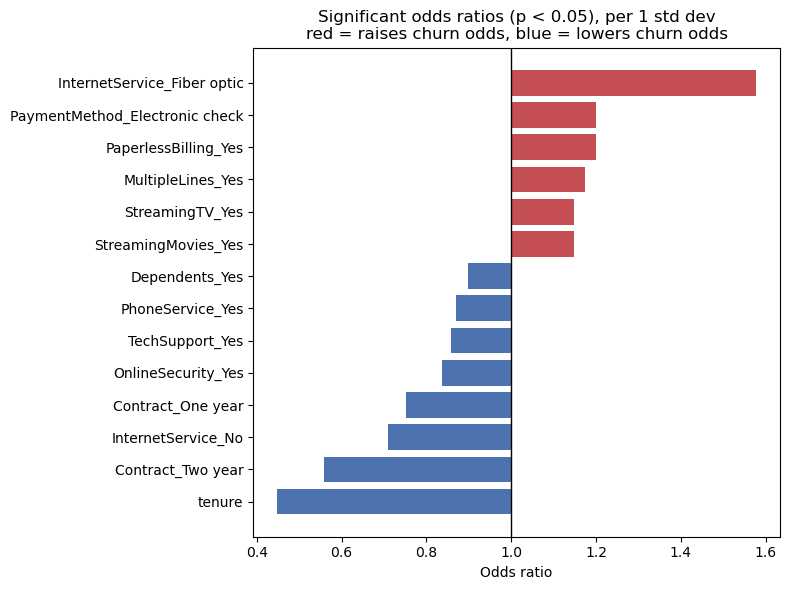

Pseudo R-squared: 0.285


In [15]:
logit = sm.Logit(y_train, sm.add_constant(Xtr)).fit(disp=0)
sig = pd.DataFrame({'coef': logit.params, 'odds_ratio': np.exp(logit.params), 'p_value': logit.pvalues}).drop('const')
sig = sig[sig['p_value'] < 0.05].sort_values('odds_ratio')
colors = ['#C44E52' if v > 1 else '#4C72B0' for v in sig['odds_ratio']]
plt.figure(figsize=(8, 6)); plt.barh(sig.index, sig['odds_ratio'] - 1, left=1, color=colors); plt.axvline(1, color='k', lw=1)
plt.title('Significant odds ratios (p < 0.05), per 1 std dev\nred = raises churn odds, blue = lowers churn odds')
plt.xlabel('Odds ratio'); plt.tight_layout(); plt.show()
print('Pseudo R-squared: %.3f' % logit.prsquared)

In [16]:
proba_test = model.predict_proba(Xte)[:, 1]          # probability of class 1 (Churn)
pred_test = (proba_test >= 0.5).astype(int)           # default threshold 0.5

sample = pd.DataFrame({'actual': y_test.values, 'predicted_probability': proba_test.round(3), 'predicted_label': pred_test},
                      index=y_test.index).head(12)
print(sample)

print('\nTest records predicted as CHURN at each threshold (out of %d):' % len(y_test))
for t in [0.3, 0.5, 0.7]:
    print(f'  threshold {t}: {(proba_test >= t).sum()} predicted positive')

      actual  predicted_probability  predicted_label
437        0                  0.031                0
2280       0                  0.704                1
2235       0                  0.066                0
4460       0                  0.402                0
3761       0                  0.022                0
5748       0                  0.624                1
3568       0                  0.469                0
2976       0                  0.139                0
5928       0                  0.005                0
1639       1                  0.389                0
2079       0                  0.222                0
1280       0                  0.046                0

Test records predicted as CHURN at each threshold (out of 1409):
  threshold 0.3: 530 predicted positive
  threshold 0.5: 322 predicted positive
  threshold 0.7: 94 predicted positive


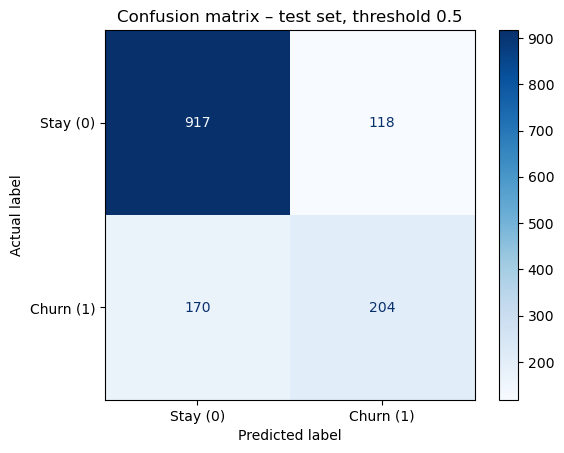

TP = 204: churners correctly flagged (retention team contacts the right customer)
FP = 118: loyal customers wrongly flagged (a wasted retention offer)
FN = 170: churners the model missed (customer is lost with no action taken)  <- costliest error
TN = 917: loyal customers correctly left alone


In [17]:
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=['Stay (0)', 'Churn (1)']).plot(cmap='Blues')
plt.title('Confusion matrix – test set, threshold 0.5'); plt.xlabel('Predicted label'); plt.ylabel('Actual label'); plt.show()
print(f'TP = {tp}: churners correctly flagged (retention team contacts the right customer)')
print(f'FP = {fp}: loyal customers wrongly flagged (a wasted retention offer)')
print(f'FN = {fn}: churners the model missed (customer is lost with no action taken)  <- costliest error')
print(f'TN = {tn}: loyal customers correctly left alone')

In [18]:
acc  = accuracy_score(y_test, pred_test)
prec = precision_score(y_test, pred_test)
rec  = recall_score(y_test, pred_test)
spec = tn / (tn + fp)
f1   = f1_score(y_test, pred_test)
auc  = roc_auc_score(y_test, proba_test)
results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall (sensitivity)', 'Specificity', 'F1-score', 'ROC-AUC'],
    'Formula': ['(TP+TN)/(TP+TN+FP+FN)', 'TP/(TP+FP)', 'TP/(TP+FN)', 'TN/(TN+FP)', '2*P*R/(P+R)', 'Area under ROC curve'],
    'Test-set result': [acc, prec, rec, spec, f1, auc]})
results['Test-set result'] = results['Test-set result'].round(3)
results

,Metric,Formula,Test-set result
0,Accuracy,(TP+TN)/(TP+TN+FP+FN),0.796
1,Precision,TP/(TP+FP),0.634
2,Recall (sensitivity),TP/(TP+FN),0.545
3,Specificity,TN/(TN+FP),0.886
4,F1-score,2*P*R/(P+R),0.586
5,ROC-AUC,Area under ROC curve,0.839


In [19]:
print(f'Accuracy    = ({tp}+{tn})/({tp}+{tn}+{fp}+{fn}) = {acc:.3f}')
print(f'Precision   = {tp}/({tp}+{fp}) = {prec:.3f}')
print(f'Recall      = {tp}/({tp}+{fn}) = {rec:.3f}')
print(f'Specificity = {tn}/({tn}+{fp}) = {spec:.3f}')
print(f'F1-score    = {f1:.3f}')
print()
print(classification_report(y_test, pred_test, target_names=['Stay', 'Churn']))

Accuracy    = (204+917)/(204+917+118+170) = 0.796
Precision   = 204/(204+118) = 0.634
Recall      = 204/(204+170) = 0.545
Specificity = 917/(917+118) = 0.886
F1-score    = 0.586

              precision    recall  f1-score   support

        Stay       0.84      0.89      0.86      1035
       Churn       0.63      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [20]:
base_pred = np.zeros_like(y_test)                       # always predict "Stay"
b_tn, b_fp, b_fn, b_tp = confusion_matrix(y_test, base_pred).ravel()
baseline = pd.DataFrame({
    'Model': ['Always predict Stay (baseline)', 'Logistic Regression (0.5)'],
    'Accuracy': [accuracy_score(y_test, base_pred), acc],
    'Recall (churn)': [0.0, rec],
    'F1 (churn)': [0.0, f1],
    'ROC-AUC': [0.5, auc]}).round(3)
baseline

,Model,Accuracy,Recall (churn),F1 (churn),ROC-AUC
0,Always predict Stay (baseline),0.735,0.000,0.000,0.500
1,Logistic Regression (0.5),0.796,0.545,0.586,0.839


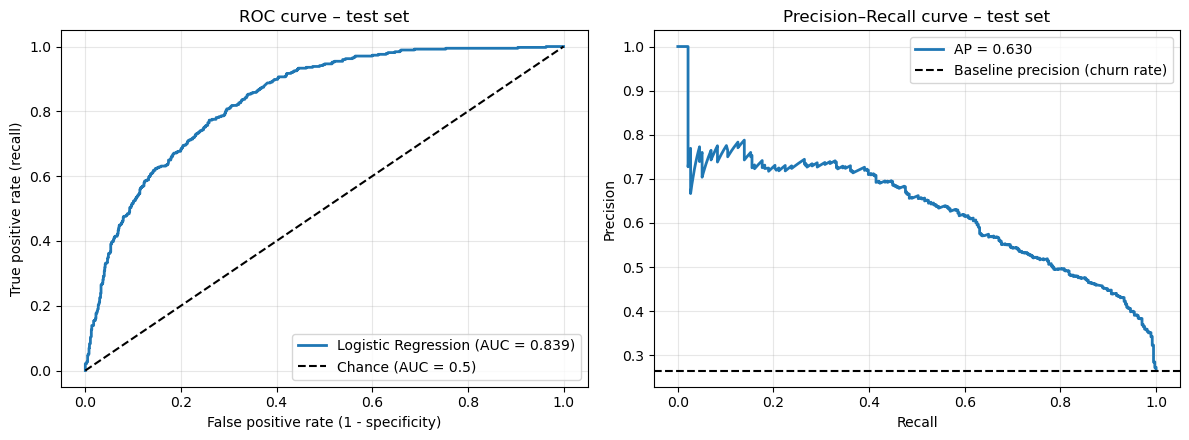

In [21]:
fpr, tpr, _ = roc_curve(y_test, proba_test)
pr_p, pr_r, _ = precision_recall_curve(y_test, proba_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(fpr, tpr, lw=2, label=f'Logistic Regression (AUC = {auc:.3f})'); ax[0].plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.5)')
ax[0].set_title('ROC curve – test set'); ax[0].set_xlabel('False positive rate (1 - specificity)'); ax[0].set_ylabel('True positive rate (recall)'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(pr_r, pr_p, lw=2, label=f'AP = {average_precision_score(y_test, proba_test):.3f}'); ax[1].axhline(y_test.mean(), color='k', ls='--', label='Baseline precision (churn rate)')
ax[1].set_title('Precision–Recall curve – test set'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [22]:
rows = []
for t in [0.3, 0.5, 0.7]:
    p_ = (proba_test >= t).astype(int)
    rows.append({'Threshold': t, 'Predicted positive': int(p_.sum()), 'Accuracy': accuracy_score(y_test, p_),
                 'Precision': precision_score(y_test, p_), 'Recall': recall_score(y_test, p_), 'F1-score': f1_score(y_test, p_)})
thr_table = pd.DataFrame(rows).round(3); thr_table

,Threshold,Predicted positive,Accuracy,Precision,Recall,F1-score
0,0.3,530,0.752,0.523,0.741,0.613
1,0.5,322,0.796,0.634,0.545,0.586
2,0.7,94,0.764,0.723,0.182,0.291


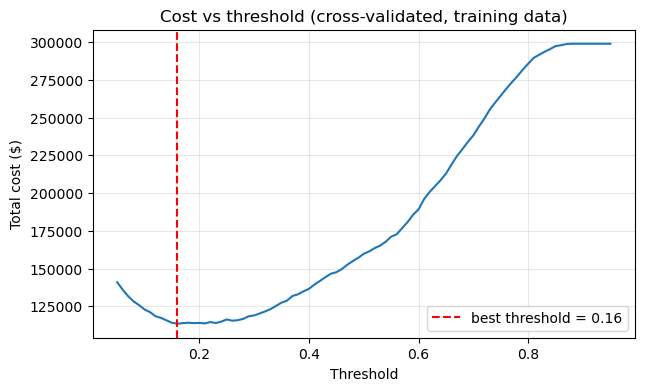

,Strategy,Recall,Precision,Customers contacted,Total cost on test set ($)
0,Contact nobody,0.000,NaN,0,74800
1,Threshold 0.5,0.545,0.634,322,39900
2,Recommended threshold 0.16,0.904,0.447,756,28100


In [23]:
COST_FP, COST_FN = 50, 200
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
proba_cv = cross_val_predict(LogisticRegression(max_iter=1000, random_state=SEED), Xtr, y_train, cv=cv, method='predict_proba')[:, 1]

grid = np.linspace(0.05, 0.95, 91)
cv_cost = []
for t in grid:
    a, b, c, d = confusion_matrix(y_train, (proba_cv >= t).astype(int)).ravel()
    cv_cost.append(b * COST_FP + c * COST_FN)
best_t = float(grid[int(np.argmin(cv_cost))])

plt.figure(figsize=(7, 4)); plt.plot(grid, cv_cost); plt.axvline(best_t, color='r', ls='--', label=f'best threshold = {best_t:.2f}')
plt.title('Cost vs threshold (cross-validated, training data)'); plt.xlabel('Threshold'); plt.ylabel('Total cost ($)'); plt.legend(); plt.grid(alpha=.3); plt.show()

# One final look on the untouched test set
pred_best = (proba_test >= best_t).astype(int)
tn2, fp2, fn2, tp2 = confusion_matrix(y_test, pred_best).ravel()
def cost(fp_, fn_): return fp_ * COST_FP + fn_ * COST_FN
final = pd.DataFrame({
    'Strategy': ['Contact nobody', 'Threshold 0.5', f'Recommended threshold {best_t:.2f}'],
    'Recall': [0, recall_score(y_test, pred_test), recall_score(y_test, pred_best)],
    'Precision': [np.nan, precision_score(y_test, pred_test), precision_score(y_test, pred_best)],
    'Customers contacted': [0, int(pred_test.sum()), int(pred_best.sum())],
    'Total cost on test set ($)': [cost(0, int(y_test.sum())), cost(fp, fn), cost(fp2, fn2)]}).round(3)
final

In [25]:
proba_train = model.predict_proba(Xtr)[:, 1]
pred_train = (proba_train >= 0.5).astype(int)
comp = pd.DataFrame({
    'Set': ['Train', 'Test'],
    'Accuracy': [accuracy_score(y_train, pred_train), acc],
    'Precision': [precision_score(y_train, pred_train), prec],
    'Recall': [recall_score(y_train, pred_train), rec],
    'F1-score': [f1_score(y_train, pred_train), f1],
    'ROC-AUC': [roc_auc_score(y_train, proba_train), auc]}).round(3)
comp

,Set,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Train,0.804,0.659,0.544,0.596,0.848
1,Test,0.796,0.634,0.545,0.586,0.839


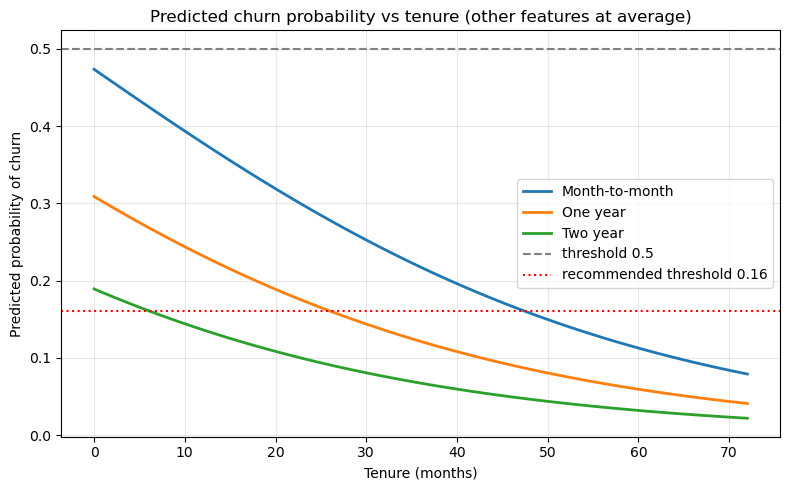

In [26]:
tenures = np.arange(0, 73)
base_row = X_train_r.mean()
plt.figure(figsize=(8, 5))
for label, cols in [('Month-to-month', {}), ('One year', {'Contract_One year': 1.0}), ('Two year', {'Contract_Two year': 1.0})]:
    grid_df = pd.DataFrame([base_row] * len(tenures)).reset_index(drop=True)
    grid_df['Contract_One year'] = 0.0; grid_df['Contract_Two year'] = 0.0
    for k, v in cols.items(): grid_df[k] = v
    grid_df['tenure'] = tenures
    plt.plot(tenures, model.predict_proba(scaler.transform(grid_df))[:, 1], lw=2, label=label)
plt.axhline(0.5, color='gray', ls='--', label='threshold 0.5'); plt.axhline(best_t, color='red', ls=':', label=f'recommended threshold {best_t:.2f}')
plt.title('Predicted churn probability vs tenure (other features at average)')
plt.xlabel('Tenure (months)'); plt.ylabel('Predicted probability of churn'); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [27]:
new_customer = {'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 4,
                'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'Fiber optic', 'OnlineSecurity': 'No',
                'OnlineBackup': 'No', 'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'Yes',
                'StreamingMovies': 'No', 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
                'PaymentMethod': 'Electronic check', 'MonthlyCharges': 80.0, 'TotalCharges': 320.0}
new = pd.DataFrame([new_customer])
new = pd.get_dummies(new).reindex(columns=X_train_r.columns, fill_value=0).astype(float)   # same encoding as training
p_new = model.predict_proba(scaler.transform(new))[:, 1][0]                                # same scaler as training
print(f'Predicted churn probability: {p_new:.3f}')
print('Class at threshold 0.50 :', 'CHURN' if p_new >= 0.5 else 'STAY')
print(f'Class at threshold {best_t:.2f} :', 'CHURN' if p_new >= best_t else 'STAY')

Predicted churn probability: 0.732
Class at threshold 0.50 : CHURN
Class at threshold 0.16 : CHURN


##  Conclusion, limitations and ethics

**Summary.** Dataset: IBM Telco churn (7,043 customers, 26.5% churn). Preparation: cleaned `TotalCharges`, dropped the ID, one-hot encoded categories, removed the multicollinear charge columns (VIF > 800 → 2.8), stratified 80:20 split, scaling fitted on training data only. Model: Logistic Regression. Result at threshold 0.5: accuracy about 0.80, precision about 0.63, recall about 0.55, specificity about 0.89, F1 about 0.59, ROC-AUC about 0.84, clearly better than the 73.5% always-Stay baseline on the metrics that matter. Recommended threshold about 0.16 (chosen on training data by expected cost) catches about 90% of churners at the cost of lower precision.

**Limitations.**
- The cost figures ($50 offer, 40% save rate, $500 customer value) are illustrative; real values would change the best threshold.
- The data is a single snapshot with no time dimension and no reasons for leaving; the model finds associations, not causes.
- Predicted probabilities are not guaranteed to be perfectly calibrated, and the model was not checked for fairness across groups.
- Dropping the charge columns changes how service coefficients (such as fiber optic) should be read.

**What this model should NOT be used for.** It should not decide on its own to refuse service, raise prices or penalise a customer; it should only help a human team prioritise who to contact with a retention offer.

**Ethics.** The dataset is a public sample with no real personal data. A wrong prediction mainly means a wasted offer (false positive) or a lost customer (false negative); decisions about people should keep a human in the loop, and sensitive attributes such as gender and senior-citizen status should be reviewed for fairness before any real deployment.